# Week 7 — Exploratory Data Analysis (EDA)

**Internship phase:** Machine Learning  
**Dataset:** Synthetic Customer Churn (continued from Week 6)  
**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, SciPy  

## Objective

Perform end-to-end EDA including univariate, bivariate and multivariate analysis; correlation, distribution, outlier and feature-relationship analysis; at least 10 visualizations; and written key findings.

> **Dataset note:** This is an artificially generated educational dataset with 500 unique customer records and 8 exact duplicate rows in the raw file. It contains no real customer information. The data-generation rules influence the churn labels, so observed patterns are for practice only and are not business evidence.

## 1. Import libraries and set project paths

Pandas is used to inspect and summarize tabular data. NumPy supports numeric operations. Matplotlib and Seaborn create visualizations. SciPy provides a supplementary chi-square association test.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Image

# Supports running the notebook from notebooks/ or from the project root.
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.eda import (
    load_data, audit_and_prepare, descriptive_statistics,
    categorical_frequency, iqr_outlier_summary, churn_rate_by_category,
    categorical_chi_square, build_summary, create_visualizations, run_eda,
    NUMERIC, CATEGORICAL, TARGET
)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)

## 2. Load the dataset

The raw data is preserved. We inspect its dimensions, columns, data types, first records and last records before any analysis.

In [2]:
raw = load_data(PROJECT_ROOT / "data/raw/customer_churn_raw.csv")
print("Shape:", raw.shape)
print("Columns:", raw.columns.tolist())
display(raw.head())
display(raw.tail())

Shape: (508, 11)
Columns: ['CustomerID', 'Age', 'TenureMonths', 'MonthlyCharges', 'TotalCharges', 'SupportCalls', 'ContractType', 'PaymentMethod', 'InternetService', 'PaperlessBilling', 'Churn']


,CustomerID,Age,TenureMonths,MonthlyCharges,TotalCharges,SupportCalls,ContractType,PaymentMethod,InternetService,PaperlessBilling,Churn
0,CUST0001,-5.0,31.0,25.15,716.90,2.0,Month-to-month,Credit card,No internet,Yes,No
1,CUST0002,145.0,19.0,95.04,1848.29,3.0,Month-to-month,Bank transfer,Fiber optic,Yes,No
2,CUST0003,31.0,150.0,101.02,7141.98,1.0,Month-to-month,Bank transfer,Fiber optic,No,Yes
3,CUST0004,49.0,68.0,999.00,3671.66,1.0,Month-to-month,Bank transfer,Fiber optic,Yes,No
4,CUST0005,56.0,42.0,79.48,-250.00,3.0,Month-to-month,Mailed check,Fiber optic,Yes,Yes


,CustomerID,Age,TenureMonths,MonthlyCharges,TotalCharges,SupportCalls,ContractType,PaymentMethod,InternetService,PaperlessBilling,Churn
503,CUST0104,48.0,25.0,59.71,1524.52,2.0,Two year,Electronic check,Fiber optic,Yes,No
504,CUST0167,26.0,54.0,75.85,4061.49,1.0,Month-to-month,Bank transfer,Fiber optic,NaN,No
505,CUST0208,46.0,25.0,NaN,2172.99,5.0,Month-to-month,Electronic check,Fiber optic,No,Yes
506,CUST0310,NaN,28.0,99.60,2778.82,2.0,Two year,Mailed check,Fiber optic,Yes,No
507,CUST0412,42.0,1.0,40.37,62.90,2.0,One year,Credit card,Fiber optic,Yes,No


## 3. Structural inspection

`info()` shows data types and non-null counts. `describe()` summarizes numeric columns. `nunique()` helps distinguish identifiers and low-cardinality categorical features.

In [3]:
raw.info()
display(raw.describe(include="all").T)
display(raw.nunique(dropna=True).rename("unique_values").to_frame())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 508 entries, 0 to 507
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   CustomerID        508 non-null    object 
 1   Age               488 non-null    float64
 2   TenureMonths      496 non-null    float64
 3   MonthlyCharges    492 non-null    float64
 4   TotalCharges      491 non-null    float64
 5   SupportCalls      494 non-null    float64
 6   ContractType      499 non-null    object 
 7   PaymentMethod     500 non-null    object 
 8   InternetService   501 non-null    object 
 9   PaperlessBilling  501 non-null    object 
 10  Churn             508 non-null    object 
dtypes: float64(5), object(6)
memory usage: 43.8+ KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
CustomerID,508,500,CUST0208,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,488.0,NaN,NaN,NaN,42.165984,14.345084,-5.0,32.0,42.0,51.0,145.0
TenureMonths,496.0,NaN,NaN,NaN,34.991935,21.793242,0.0,16.0,34.0,52.0,150.0
MonthlyCharges,492.0,NaN,NaN,NaN,73.491789,52.923702,17.0,41.1275,74.13,96.4275,999.0
TotalCharges,491.0,NaN,NaN,NaN,2485.866273,2044.206818,-250.0,882.16,1916.32,3685.865,10020.87
SupportCalls,494.0,NaN,NaN,NaN,2.064777,2.816903,0.0,1.0,2.0,3.0,55.0
ContractType,499,3,Month-to-month,269,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PaymentMethod,500,4,Electronic check,189,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,501,3,Fiber optic,249,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PaperlessBilling,501,2,Yes,373,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,unique_values
CustomerID,500
Age,59
TenureMonths,74
MonthlyCharges,472
TotalCharges,475
SupportCalls,11
ContractType,3
PaymentMethod,4
InternetService,3
PaperlessBilling,2


## 4. Data quality audit and analysis copy

We count exact duplicates and missing values. Then we remove exact duplicate rows from the analysis copy and mark impossible numeric values as missing using the Week 6 domain rules. We do **not** impute missing values in EDA because filling values can obscure the observed data quality and alter descriptive distributions.

In [4]:
raw_missing = raw.isna().sum().sort_values(ascending=False)
print("Exact duplicate rows:", raw.duplicated().sum())
display(raw_missing.rename("missing_count").to_frame())

analysis_df, audit = audit_and_prepare(raw)
print(json.dumps(audit, indent=2))
analysis_df.to_csv(PROJECT_ROOT / "data/processed/customer_churn_eda_audited.csv", index=False)

Exact duplicate rows: 8


,missing_count
Age,20
TotalCharges,17
MonthlyCharges,16
SupportCalls,14
TenureMonths,12
ContractType,9
PaymentMethod,8
PaperlessBilling,7
InternetService,7
CustomerID,0


{
  "raw_rows": 508,
  "raw_columns": 11,
  "exact_duplicate_rows": 8,
  "rows_after_exact_deduplication": 500,
  "raw_missing_by_column": {
    "CustomerID": 0,
    "Age": 20,
    "TenureMonths": 12,
    "MonthlyCharges": 16,
    "TotalCharges": 17,
    "SupportCalls": 14,
    "ContractType": 9,
    "PaymentMethod": 8,
    "InternetService": 7,
    "PaperlessBilling": 7,
    "Churn": 0
  },
  "invalid_domain_values_marked_missing": {
    "Age": 2,
    "TenureMonths": 1,
    "MonthlyCharges": 1,
    "TotalCharges": 1,
    "SupportCalls": 1
  },
  "analysis_missing_by_column_after_domain_validation": {
    "CustomerID": 0,
    "Age": 20,
    "TenureMonths": 13,
    "MonthlyCharges": 16,
    "TotalCharges": 18,
    "SupportCalls": 15,
    "ContractType": 9,
    "PaymentMethod": 8,
    "InternetService": 7,
    "PaperlessBilling": 6,
    "Churn": 0
  }
}


## 5. Univariate analysis — target distribution

Univariate analysis studies one variable at a time. First inspect class counts and percentages for the churn target. A class imbalance can affect how later model metrics should be interpreted.

In [5]:
target_counts = analysis_df[TARGET].value_counts(dropna=False).rename_axis("Churn").to_frame("count")
target_counts["percentage"] = target_counts["count"] / len(analysis_df) * 100
display(target_counts.round(2))

,count,percentage
Churn,,
No,393,78.6
Yes,107,21.4


## 6. Univariate analysis — numeric distributions

Histograms show the distribution shape. The descriptive table reports count, mean, standard deviation, quartiles, median, skewness and missingness.

In [6]:
numeric_stats = descriptive_statistics(analysis_df)
display(numeric_stats.round(3))

,feature,count,mean,std,min,25%,50%,75%,max,median,missing_count,missing_percent,skewness,iqr
0,Age,480.0,42.150,13.417,18.0,32.000,42.000,51.000,82.00,42.000,20,4.0,0.180,19.000
1,TenureMonths,487.0,34.965,21.214,0.0,16.000,35.000,52.000,72.00,35.000,13,2.6,0.088,36.000
2,MonthlyCharges,484.0,71.453,32.541,17.0,40.622,73.665,95.310,195.00,73.665,16,3.2,0.254,54.688
3,TotalCharges,482.0,2502.411,2051.803,0.0,887.042,1919.285,3696.118,10020.87,1919.285,18,3.6,1.047,2809.075
4,SupportCalls,485.0,1.953,1.499,0.0,1.000,2.000,3.000,14.00,2.000,15,3.0,2.257,2.000


## 7. Univariate analysis — categorical frequencies

Frequency counts reveal the common categories and the amount of missing categorical information.

In [7]:
category_stats = categorical_frequency(analysis_df)
display(category_stats.round(2))

,feature,category,count,percent_of_rows
0,ContractType,Month-to-month,264,52.8
1,ContractType,One year,116,23.2
2,ContractType,Two year,111,22.2
3,ContractType,MISSING,9,1.8
4,PaymentMethod,Electronic check,187,37.4
5,PaymentMethod,Bank transfer,118,23.6
6,PaymentMethod,Credit card,99,19.8
7,PaymentMethod,Mailed check,88,17.6
8,PaymentMethod,MISSING,8,1.6
9,InternetService,Fiber optic,242,48.4


## 8. Distribution and outlier analysis

The IQR method defines potential outliers as values below `Q1 - 1.5 × IQR` or above `Q3 + 1.5 × IQR`. This is a flag for investigation, not proof that a value is wrong. We retain all valid observations in the analysis.

In [8]:
outlier_stats = iqr_outlier_summary(analysis_df)
display(outlier_stats.round(3))

,feature,q1,q3,iqr,lower_fence,upper_fence,potential_outlier_count,potential_outlier_percent_of_non_missing,non_missing_count
0,Age,32.000,51.000,19.000,3.500,79.500,3,0.625,480
1,TenureMonths,16.000,52.000,36.000,-38.000,106.000,0,0.000,487
2,MonthlyCharges,40.622,95.310,54.688,-41.409,177.341,2,0.413,484
3,TotalCharges,887.042,3696.118,2809.075,-3326.570,7909.730,8,1.660,482
4,SupportCalls,1.000,3.000,2.000,-2.000,6.000,5,1.031,485


## 9. Bivariate analysis — numeric features against churn

Compare numeric distributions for customers labeled `No` and `Yes`. Medians are also inspected because they are less sensitive than means to extreme observations.

In [9]:
by_churn = analysis_df.groupby(TARGET)[NUMERIC].agg(["count", "mean", "median", "std"]).round(2)
display(by_churn)

Age                      TenureMonths                      MonthlyCharges                      TotalCharges                    \
      count   mean median    std        count   mean median    std          count   mean median    std        count     mean   median   
Churn                                                                                                                                   
No      378  42.33   42.0  13.35          383  36.85   37.0  21.13            384  69.11  71.31  32.49          379  2506.02  1927.18   
Yes     102  41.48   42.0  13.72          104  28.02   23.5  20.14            100  80.47  85.50  31.29          103  2489.15  1850.25   

               SupportCalls                     
           std        count  mean median   std  
Churn                                           
No     1993.33          382  1.87    2.0  1.53  
Yes    2264.39          103  2.24    2.0  1.33

## 10. Bivariate analysis — categorical features against churn

The churn rate for each category is the fraction of available records in that category with `Churn == Yes`. Category sample sizes are included to provide context.

In [10]:
category_churn = churn_rate_by_category(analysis_df)
display(category_churn.round(2))

,feature,category,customers,churned,churn_rate
0,ContractType,Month-to-month,264,78,29.55
1,ContractType,One year,116,19,16.38
2,ContractType,Two year,111,9,8.11
3,PaymentMethod,Bank transfer,118,25,21.19
4,PaymentMethod,Credit card,99,22,22.22
5,PaymentMethod,Electronic check,187,40,21.39
6,PaymentMethod,Mailed check,88,18,20.45
7,InternetService,DSL,155,32,20.65
8,InternetService,Fiber optic,242,56,23.14
9,InternetService,No internet,96,18,18.75


## 11. Multivariate and correlation analysis

The churn target is mapped to a binary value (`No = 0`, `Yes = 1`) only for correlation inspection. Pearson correlation measures linear association. It cannot prove causality and can miss non-linear relationships.

In [11]:
correlation_data = analysis_df[NUMERIC].copy()
correlation_data["ChurnBinary"] = analysis_df[TARGET].map({"No": 0, "Yes": 1})
correlation_matrix = correlation_data.corr(numeric_only=True)
display(correlation_matrix.round(3))

,Age,TenureMonths,MonthlyCharges,TotalCharges,SupportCalls,ChurnBinary
Age,1.000,0.031,0.039,0.069,0.049,-0.026
TenureMonths,0.031,1.000,0.023,0.739,0.007,-0.171
MonthlyCharges,0.039,0.023,1.000,0.565,0.008,0.141
TotalCharges,0.069,0.739,0.565,1.000,0.036,-0.003
SupportCalls,0.049,0.007,0.008,0.036,1.000,0.101
ChurnBinary,-0.026,-0.171,0.141,-0.003,0.101,1.000


## 12. Supplementary categorical association analysis

A chi-square test and Cramér's V are generated for categorical features against churn. Because this dataset is synthetic, do not interpret p-values as evidence about a real customer population.

In [12]:
chi_square_results = categorical_chi_square(analysis_df)
display(chi_square_results.round(4))

,feature,chi_square,degrees_of_freedom,p_value,cramers_v,n
0,ContractType,23.6493,2,0.0000,0.2195,491
1,PaymentMethod,0.0889,3,0.9931,0.0134,492
2,InternetService,0.8831,2,0.6430,0.0423,493
3,PaperlessBilling,0.0355,1,0.8506,0.0085,494


## 13. Generate and inspect all visualizations

The pipeline saves 19 charts: target count/share, missingness, numeric distributions, boxplots, categorical frequencies, numeric features by churn, violin plot, four category churn-rate plots, three scatterplots, correlation heatmap, pairplot and contract/churn heatmap.

In [13]:
run_result = run_eda(PROJECT_ROOT, make_figures=True)
print("Charts generated:", run_result["visualization_count"])
for name in run_result["visualizations"]:
    print(name)

Charts generated: 19
01_target_distribution_count.png
02_target_class_share.png
03_missing_values_by_feature.png
04_numeric_feature_distributions.png
05_numeric_boxplots.png
06_categorical_feature_frequencies.png
07_numeric_features_by_churn.png
08_monthly_charges_violin_by_churn.png
09_monthly_charges_by_contract_and_churn.png
10_churn_rate_by_contracttype.png
11_churn_rate_by_paymentmethod.png
12_churn_rate_by_internetservice.png
13_churn_rate_by_paperlessbilling.png
14_tenure_vs_total_charges.png
15_monthly_charges_vs_support_calls.png
16_correlation_heatmap.png
17_multivariate_pairplot.png
18_age_vs_tenure.png
19_contract_churn_crosstab_heatmap.png


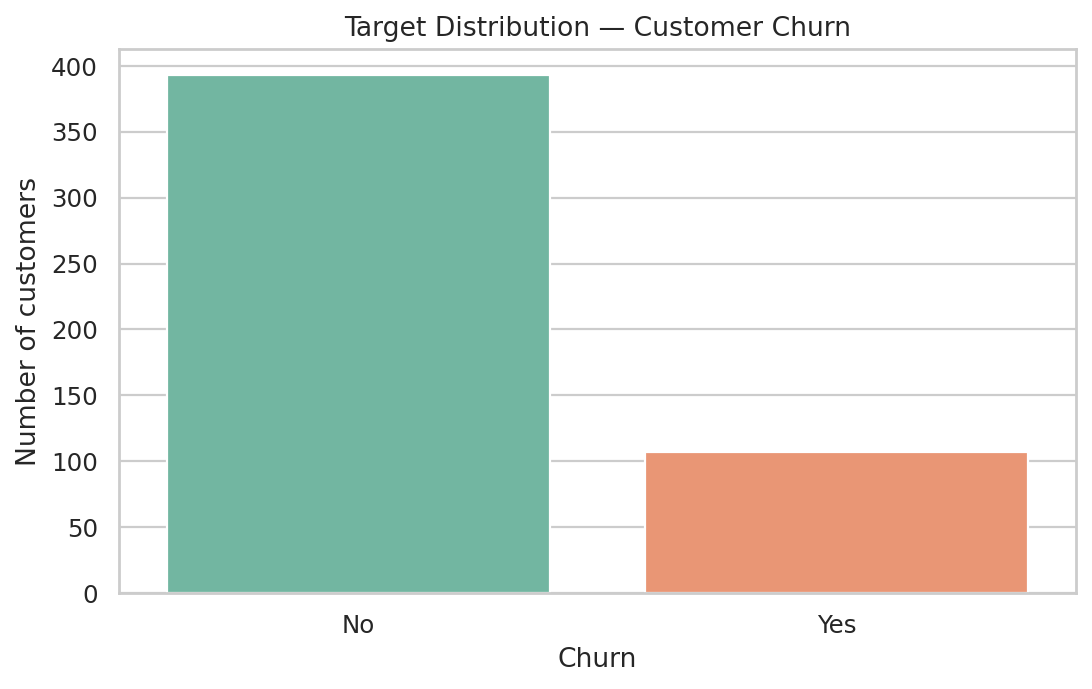

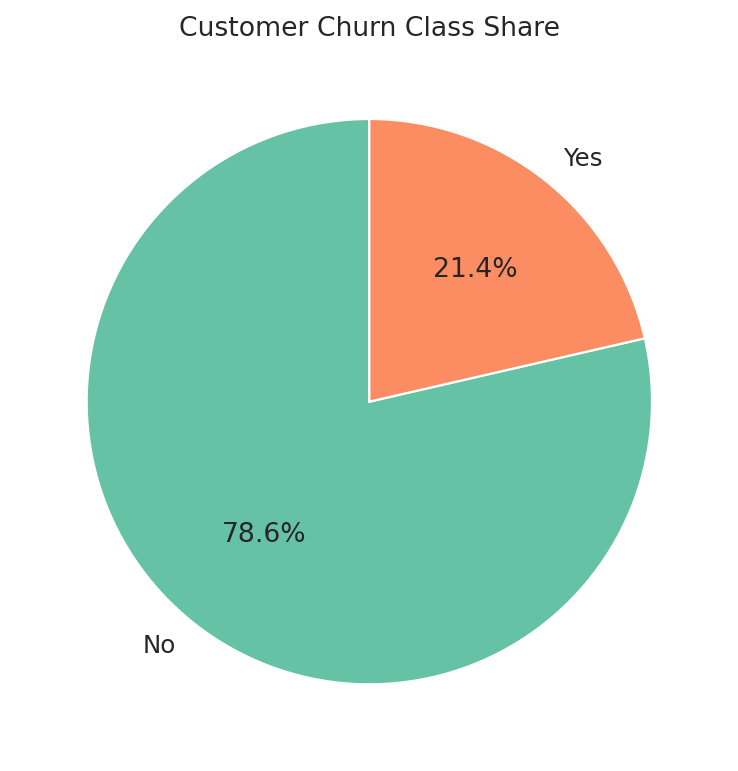

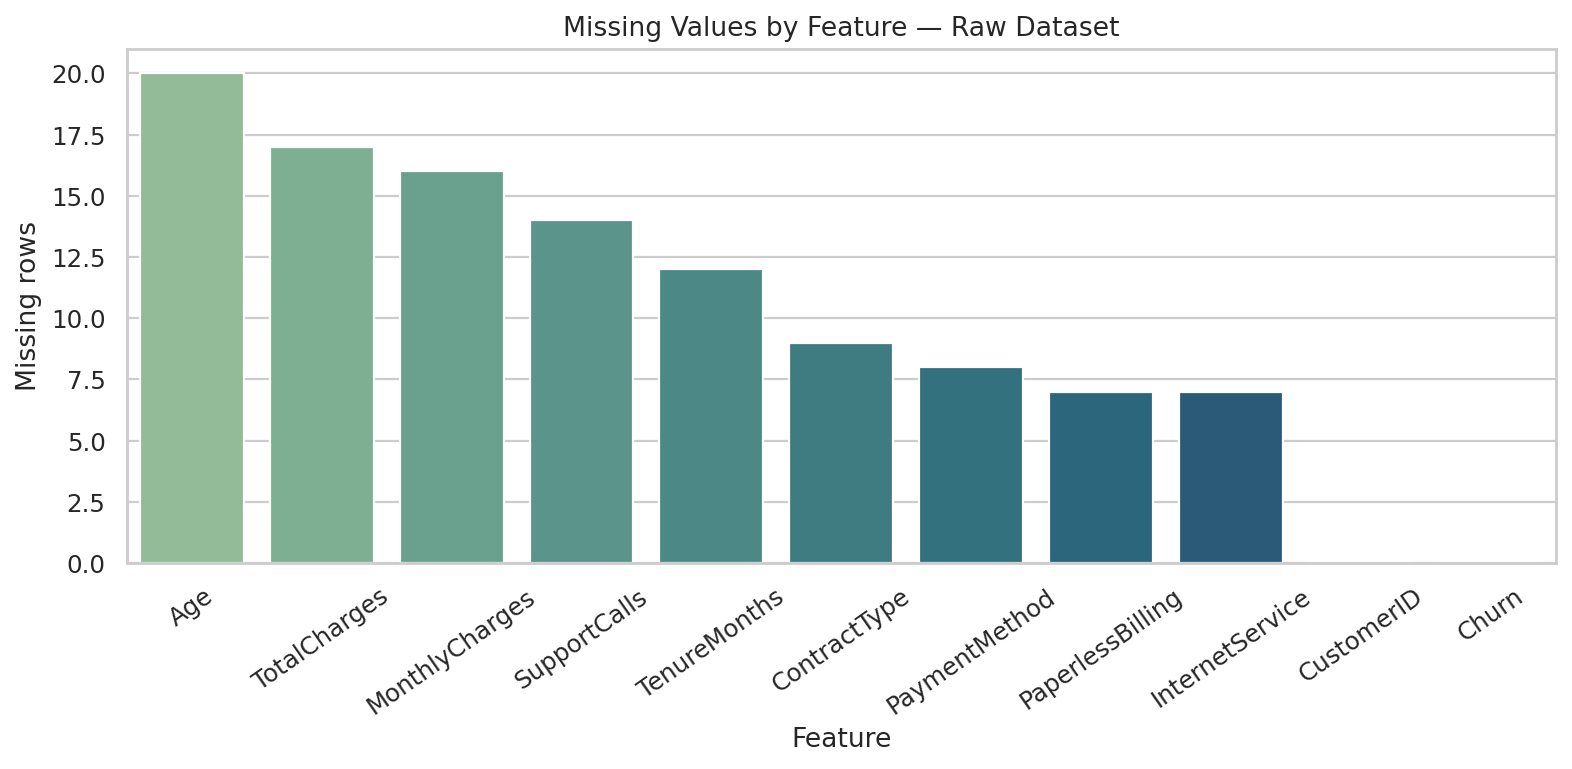

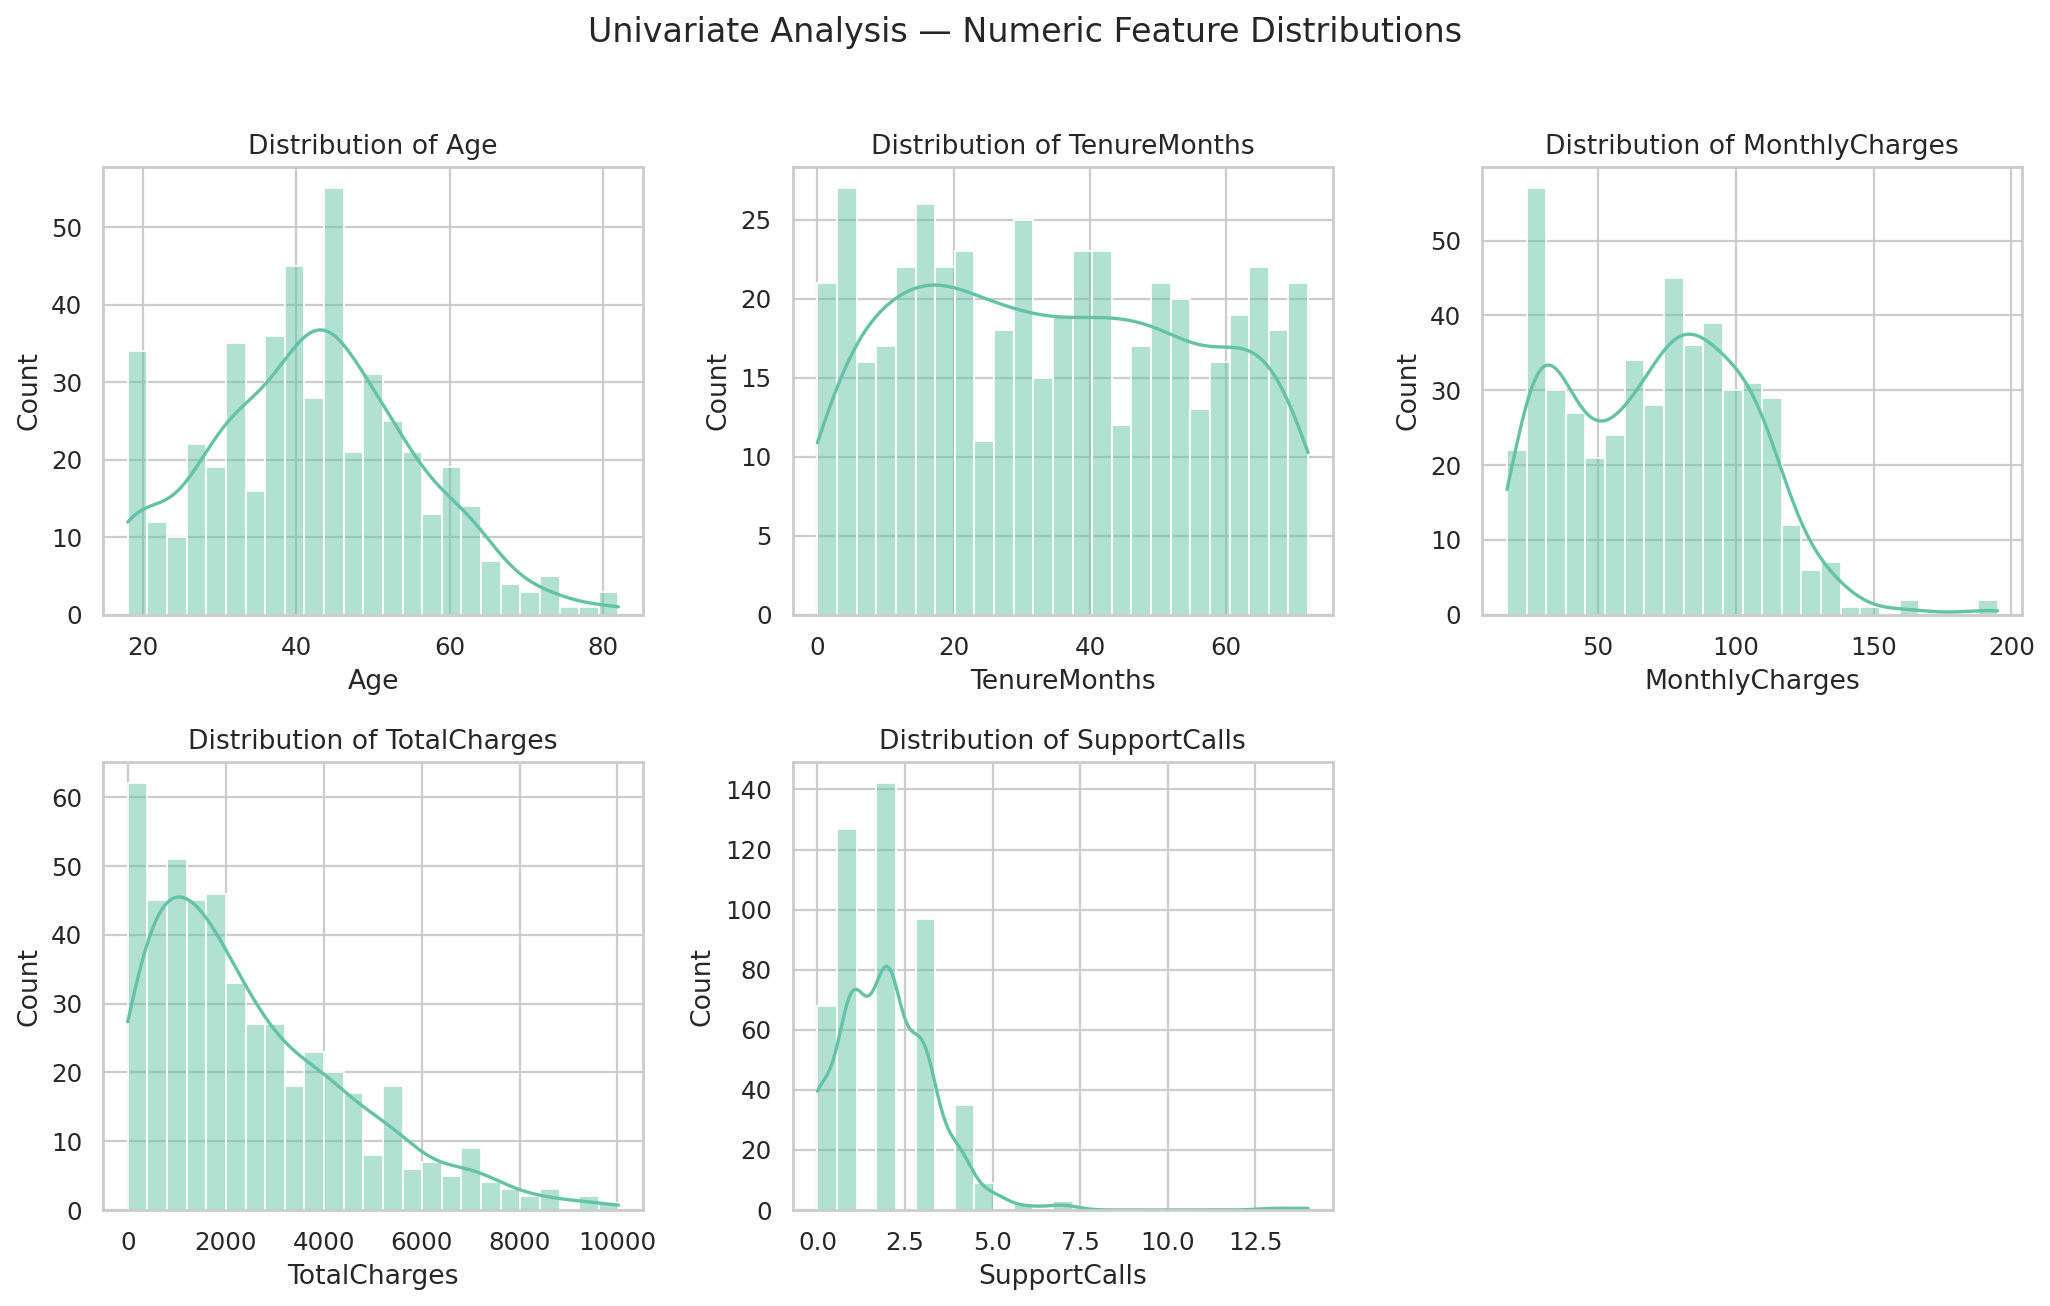

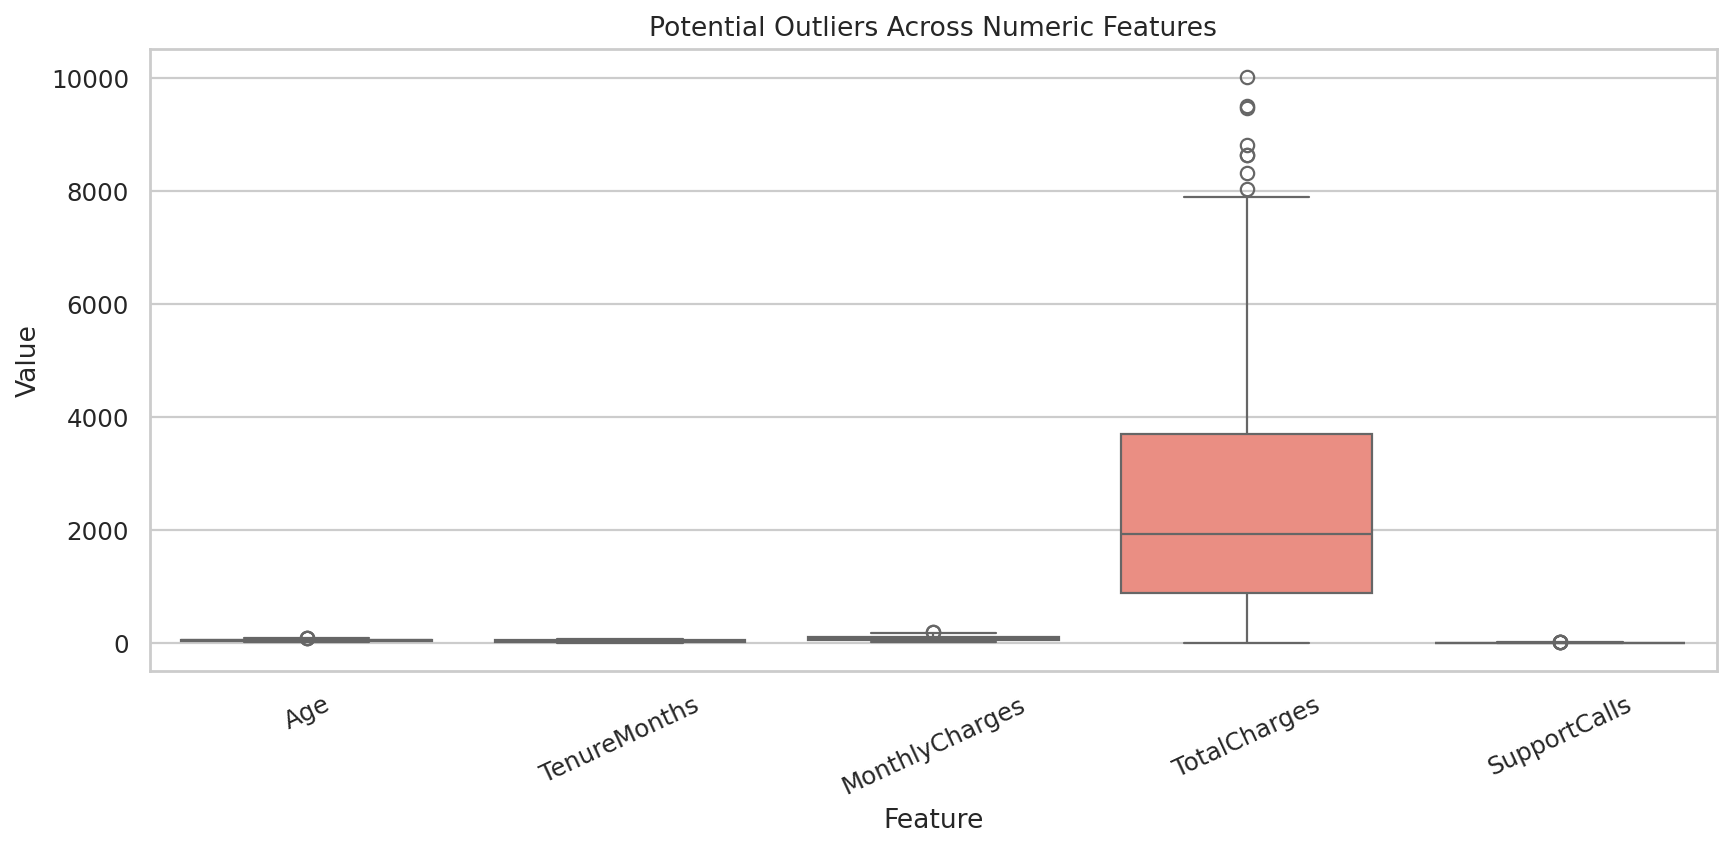

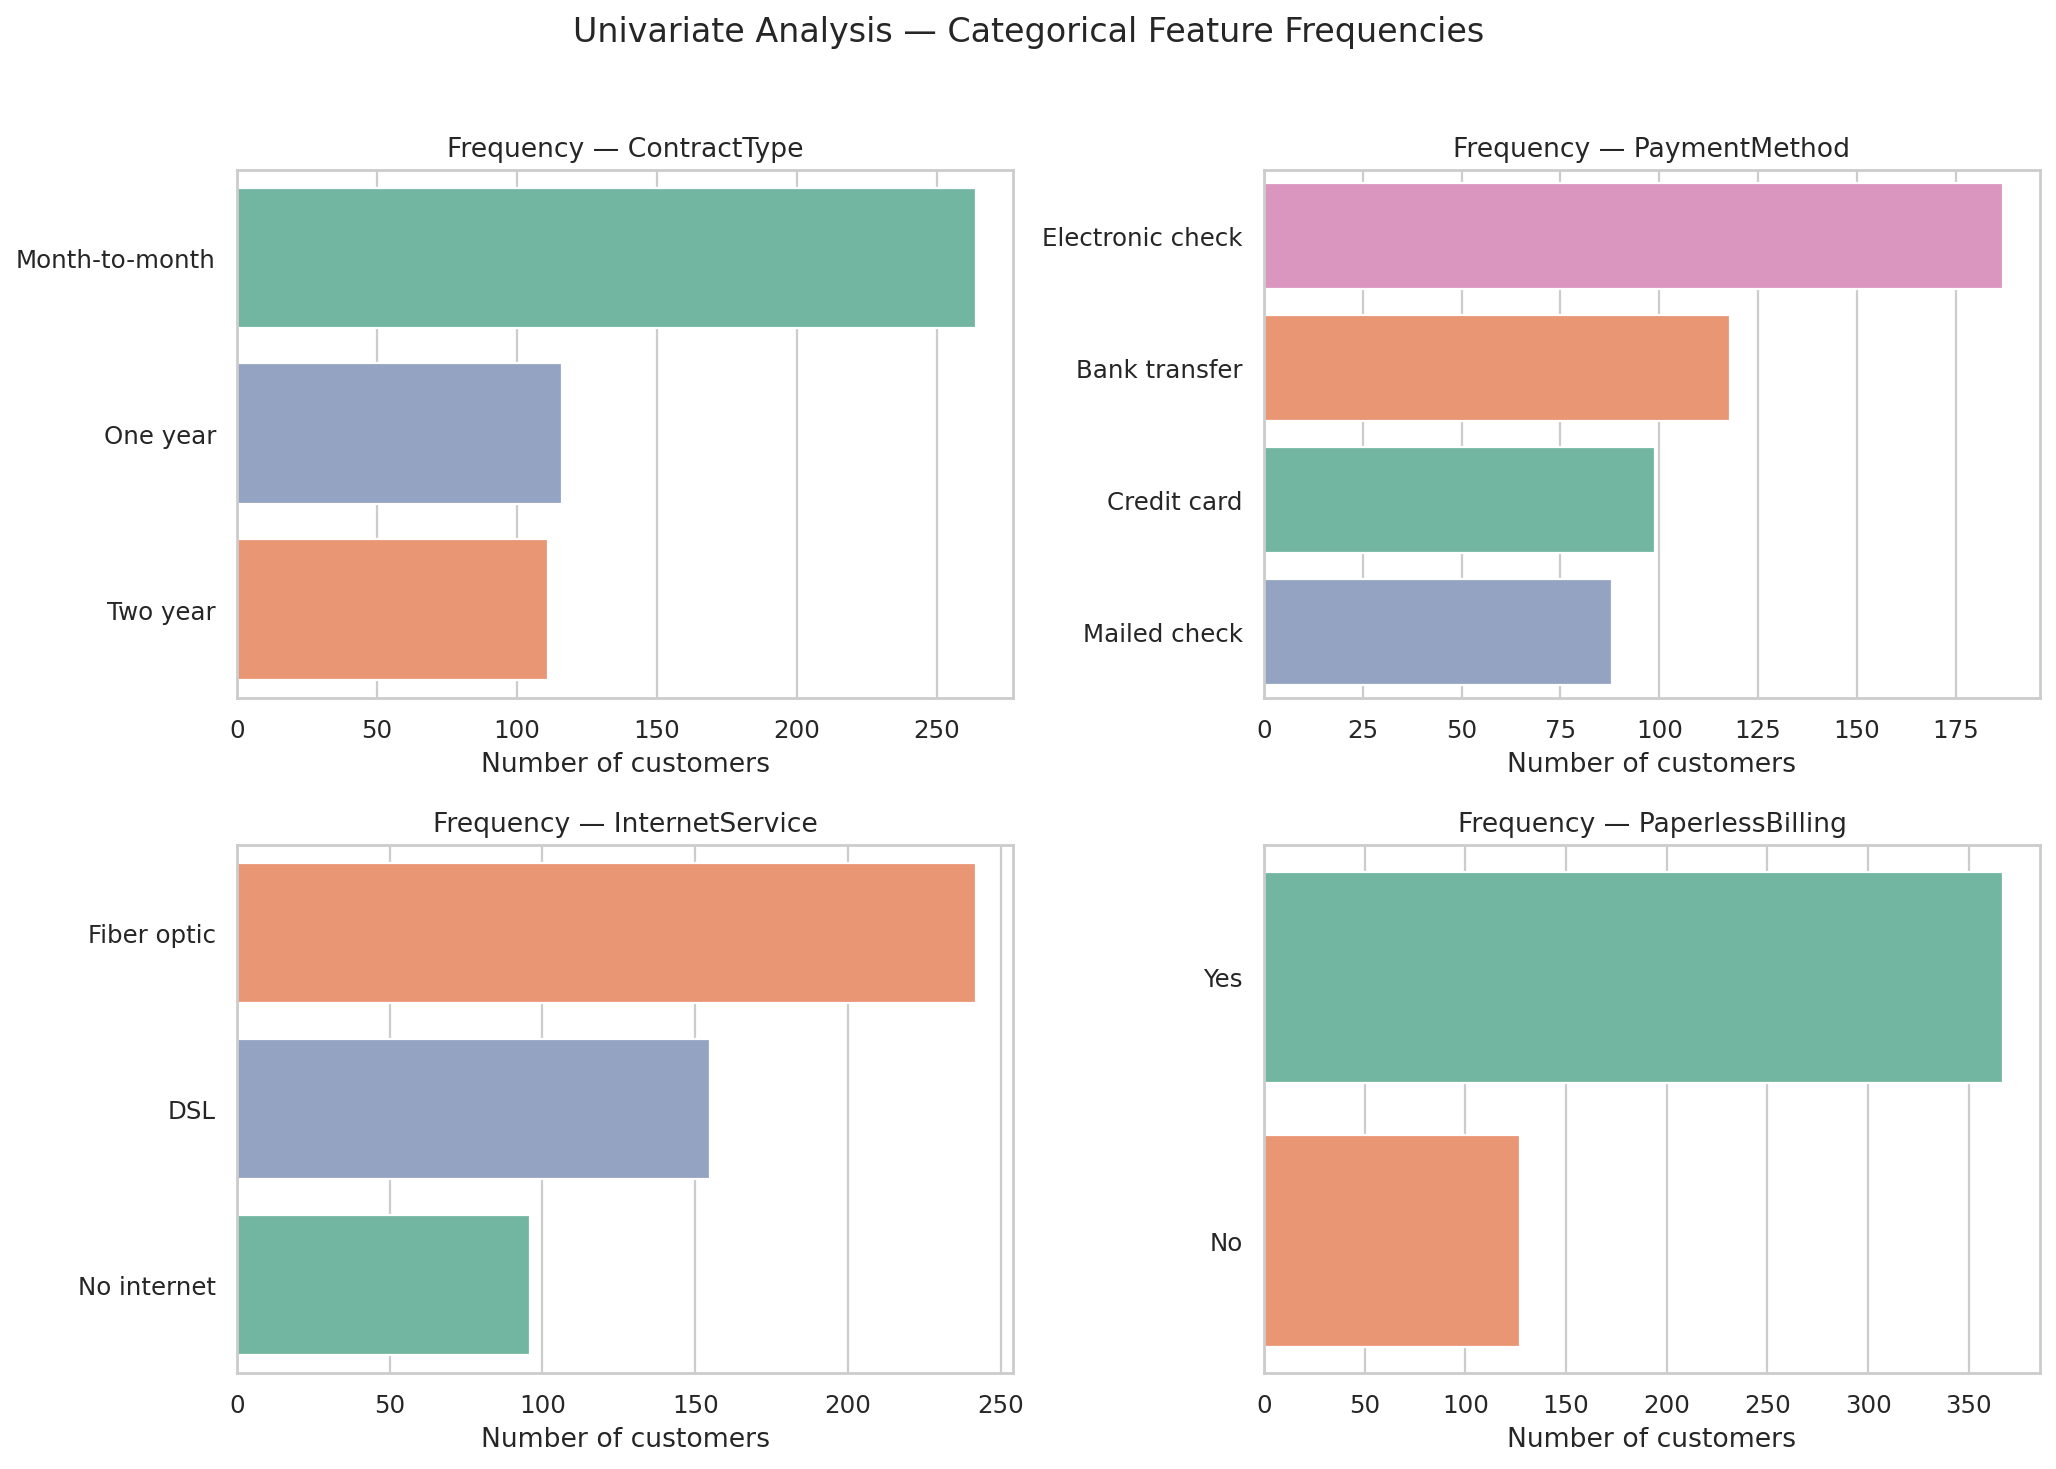

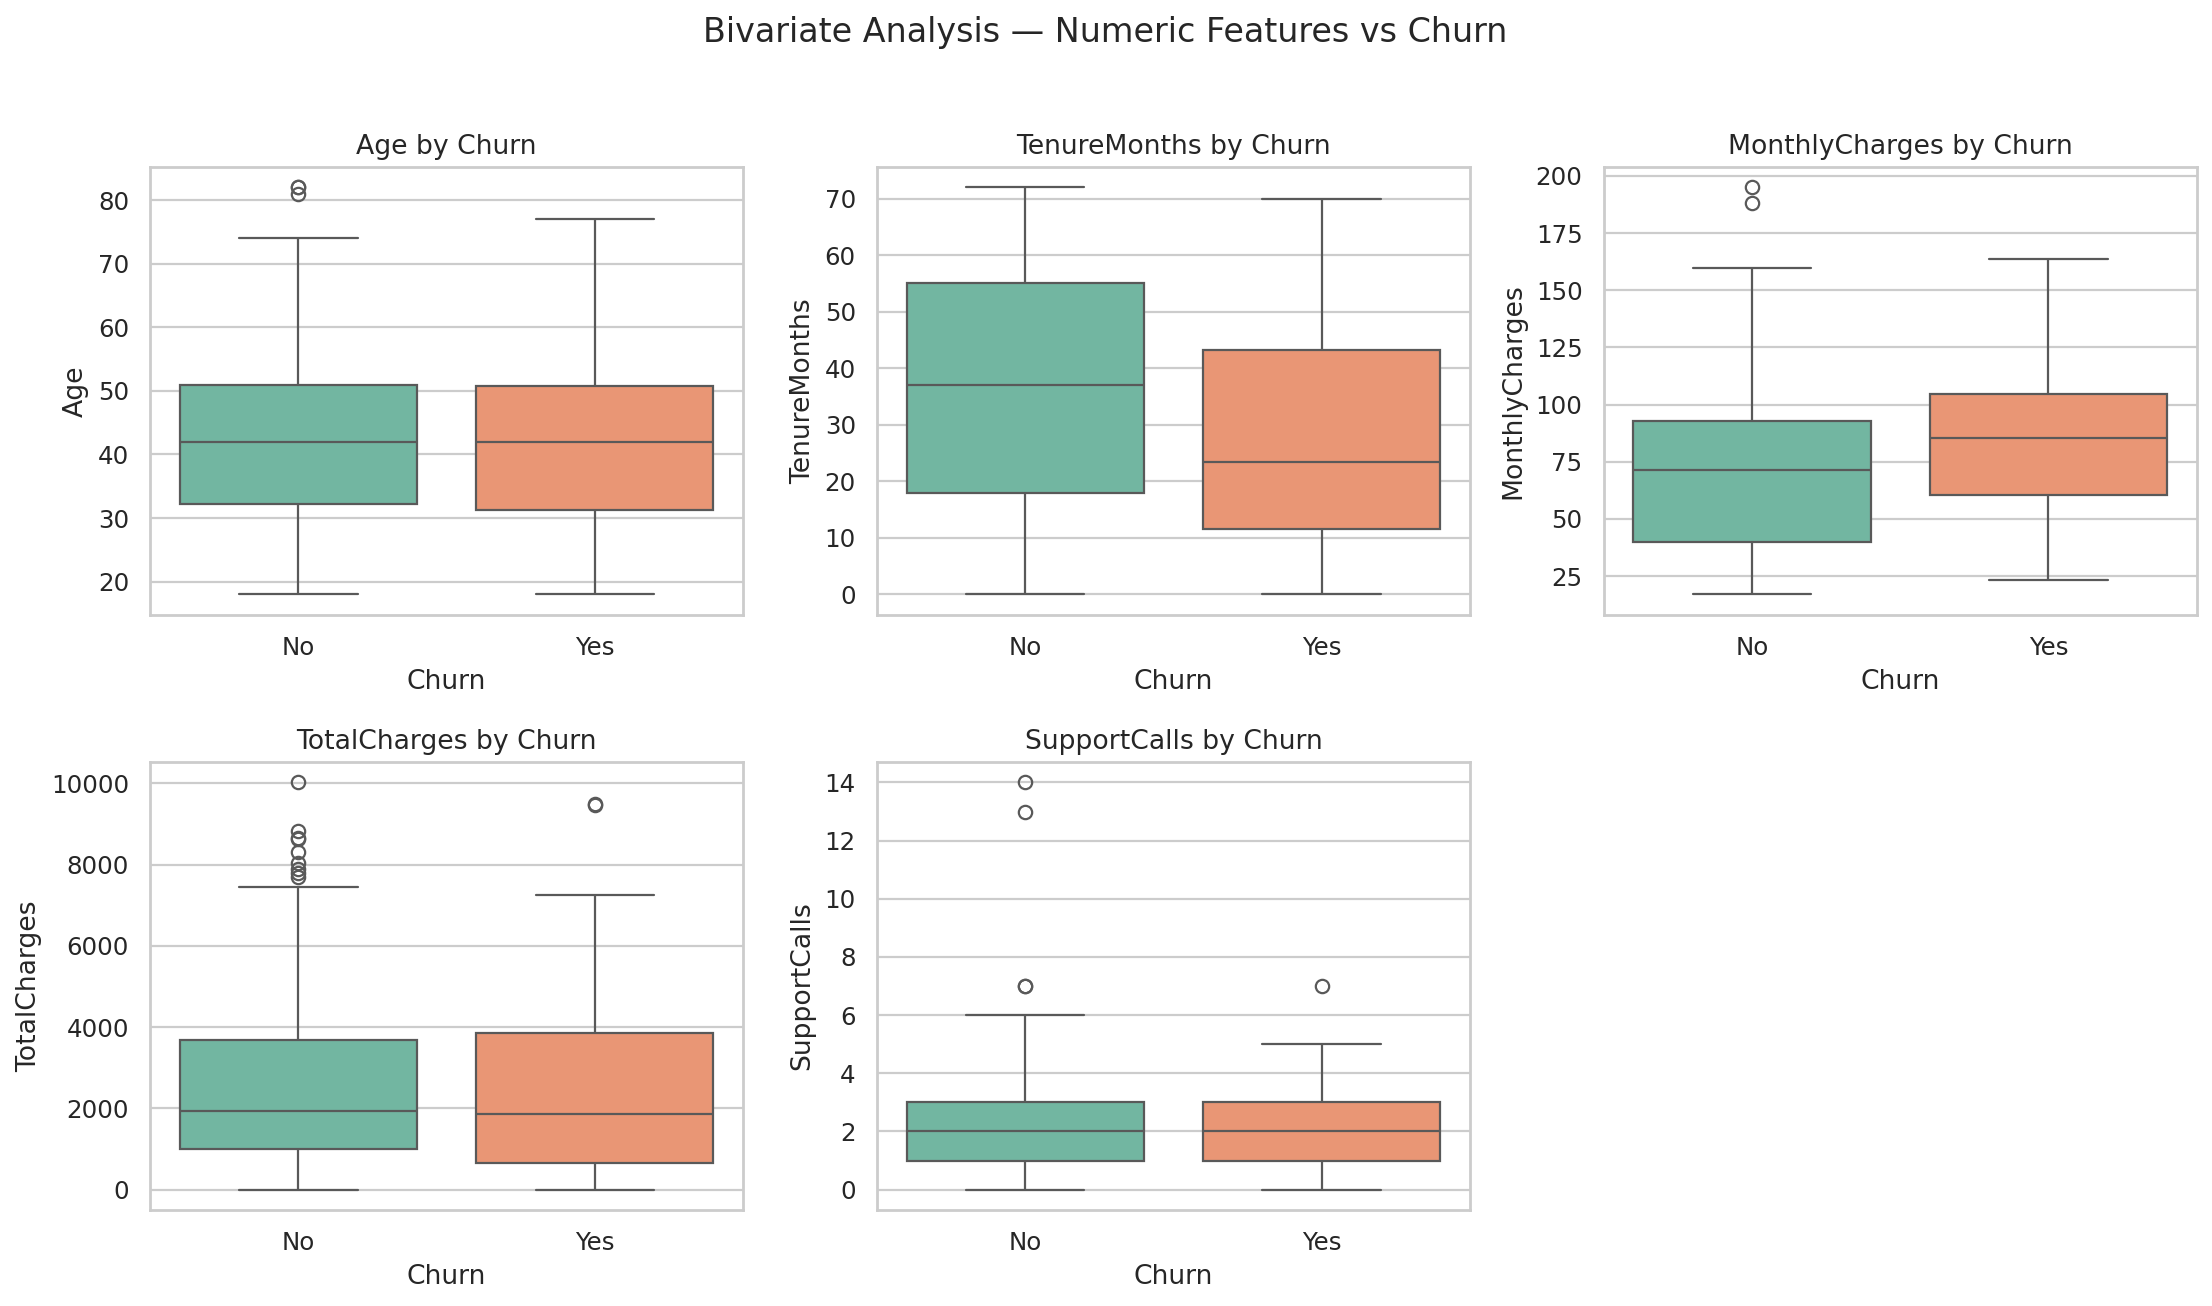

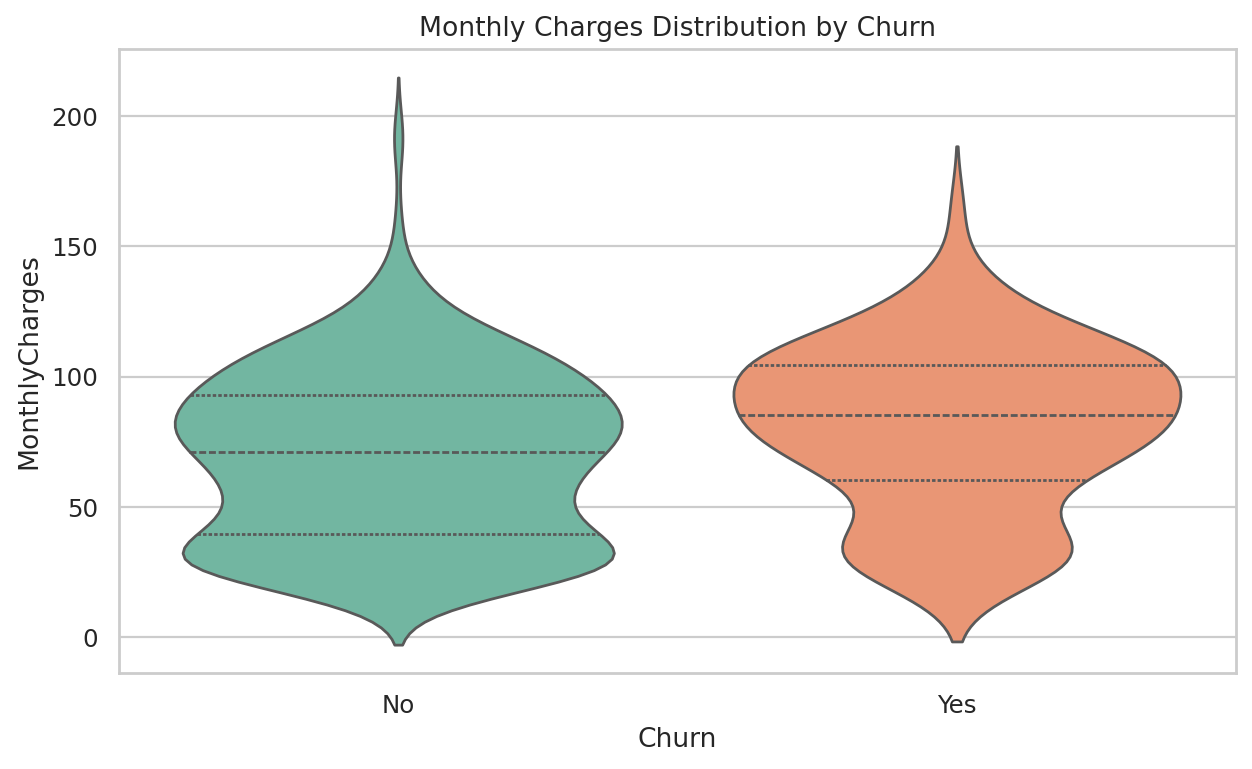

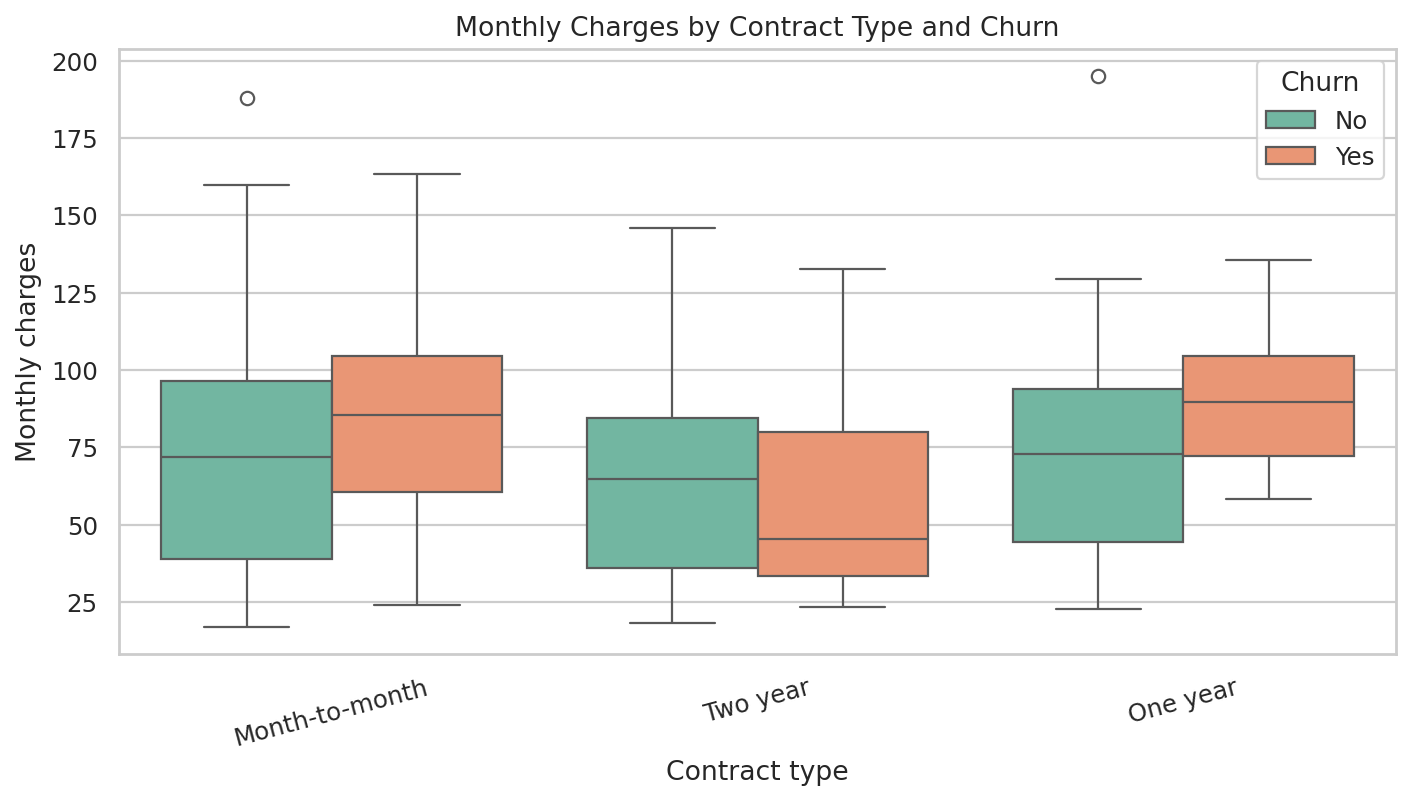

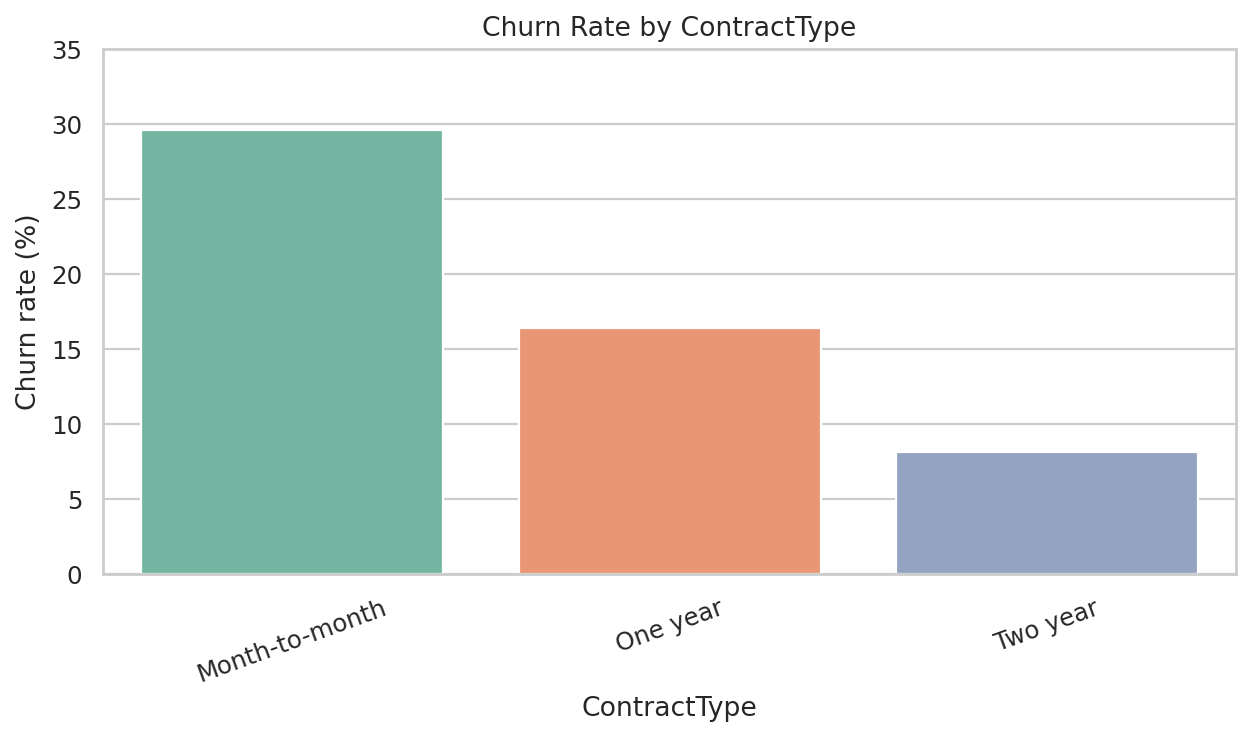

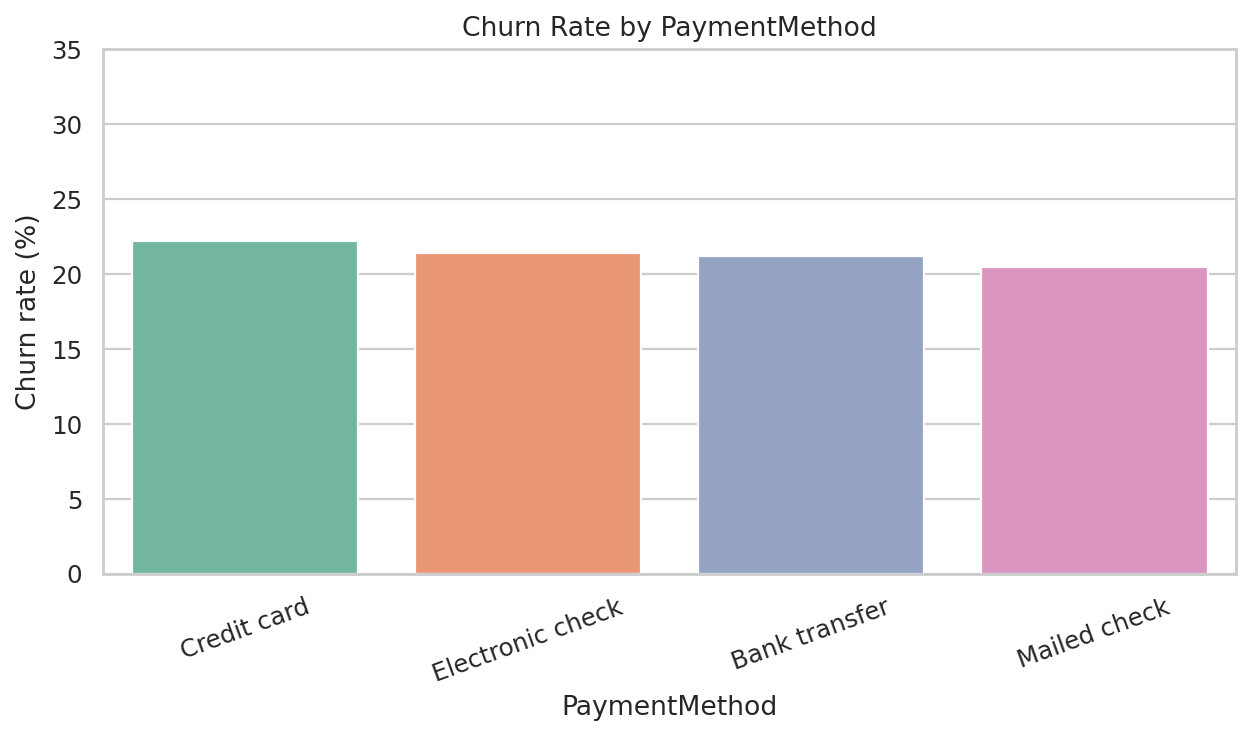

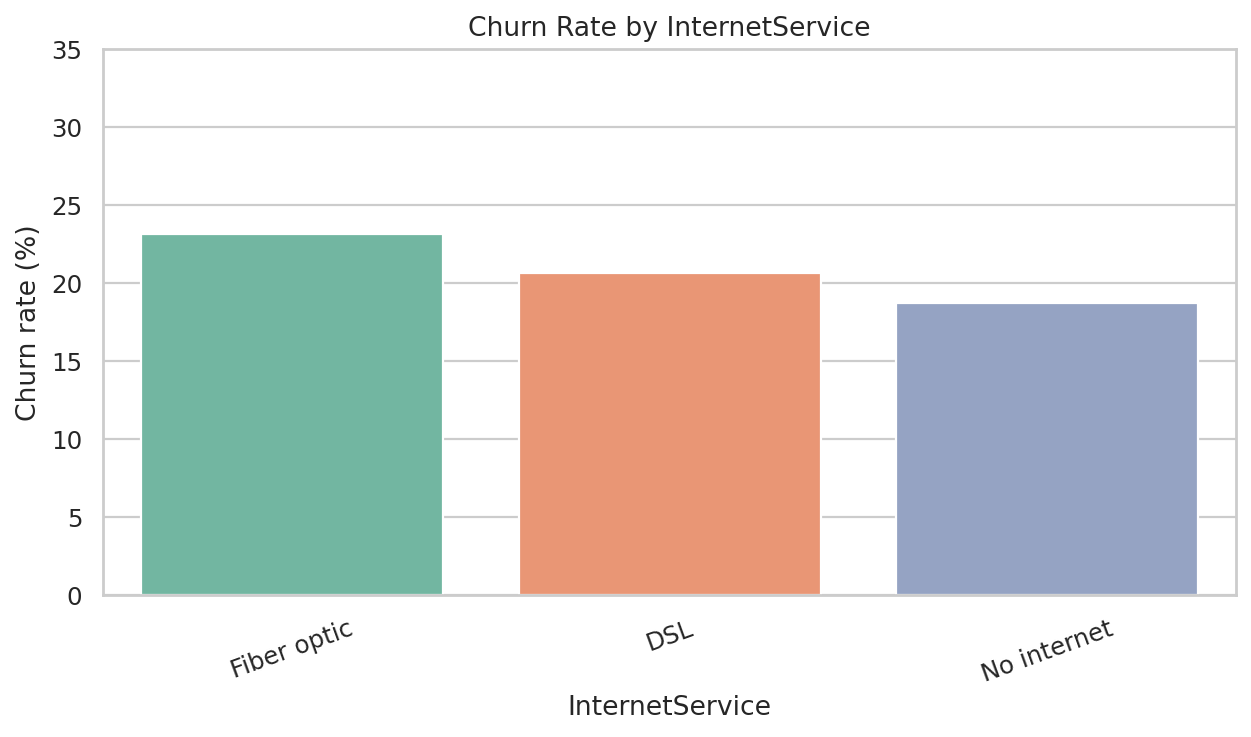

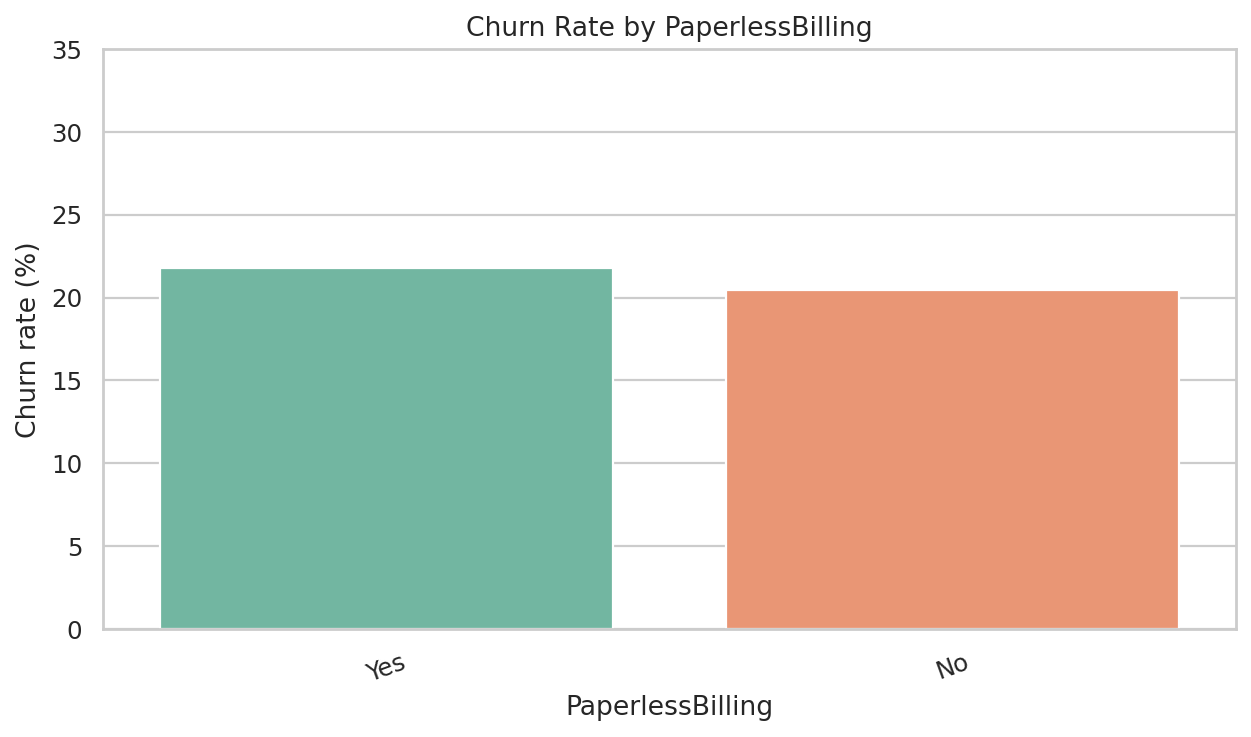

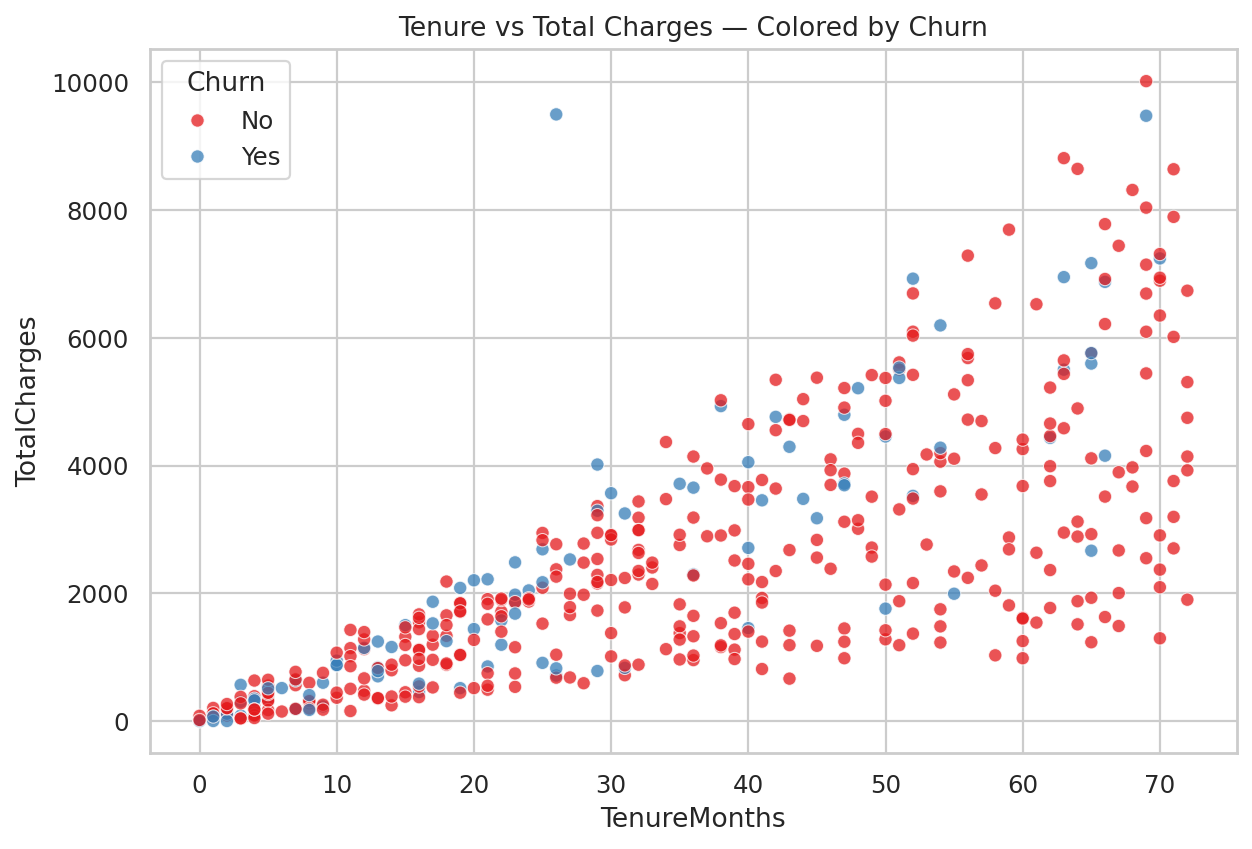

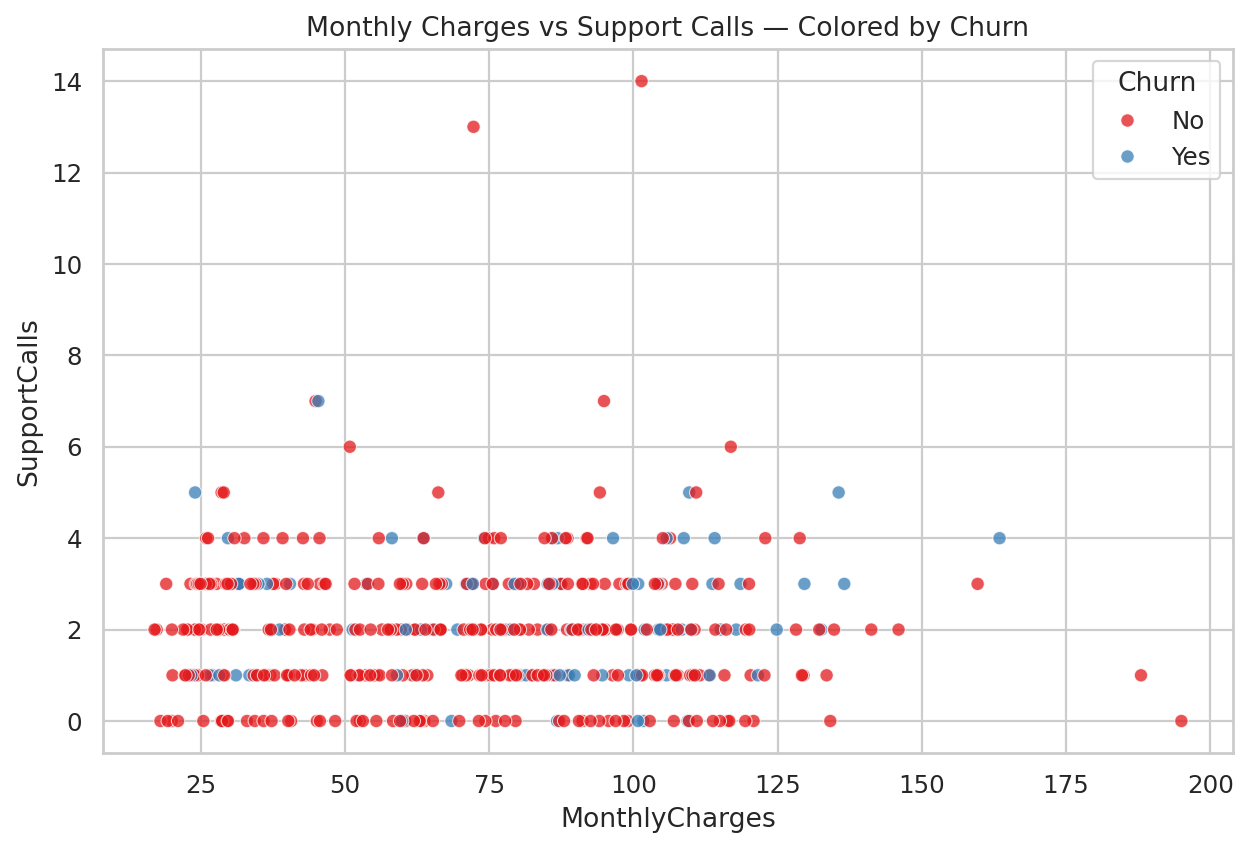

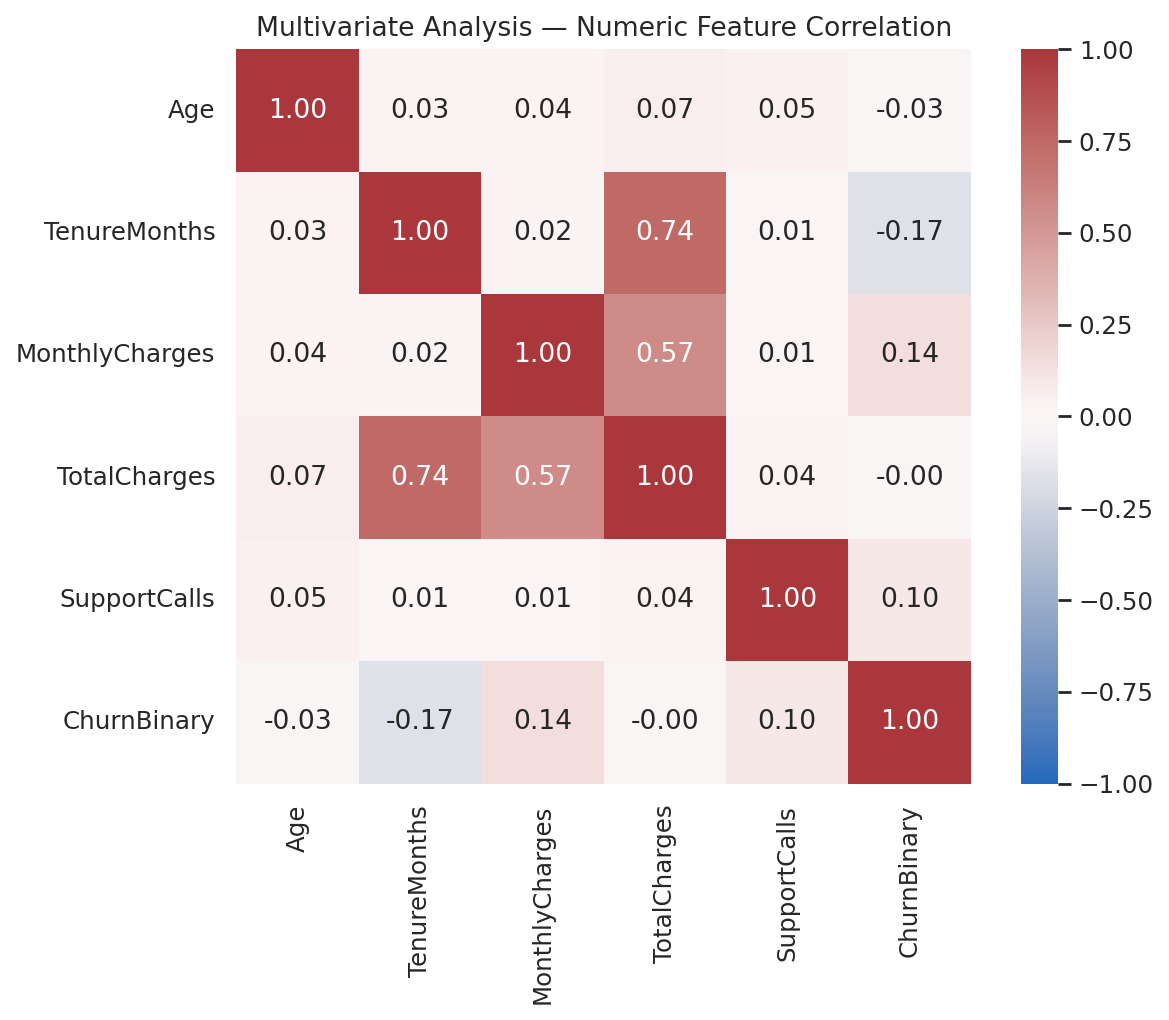

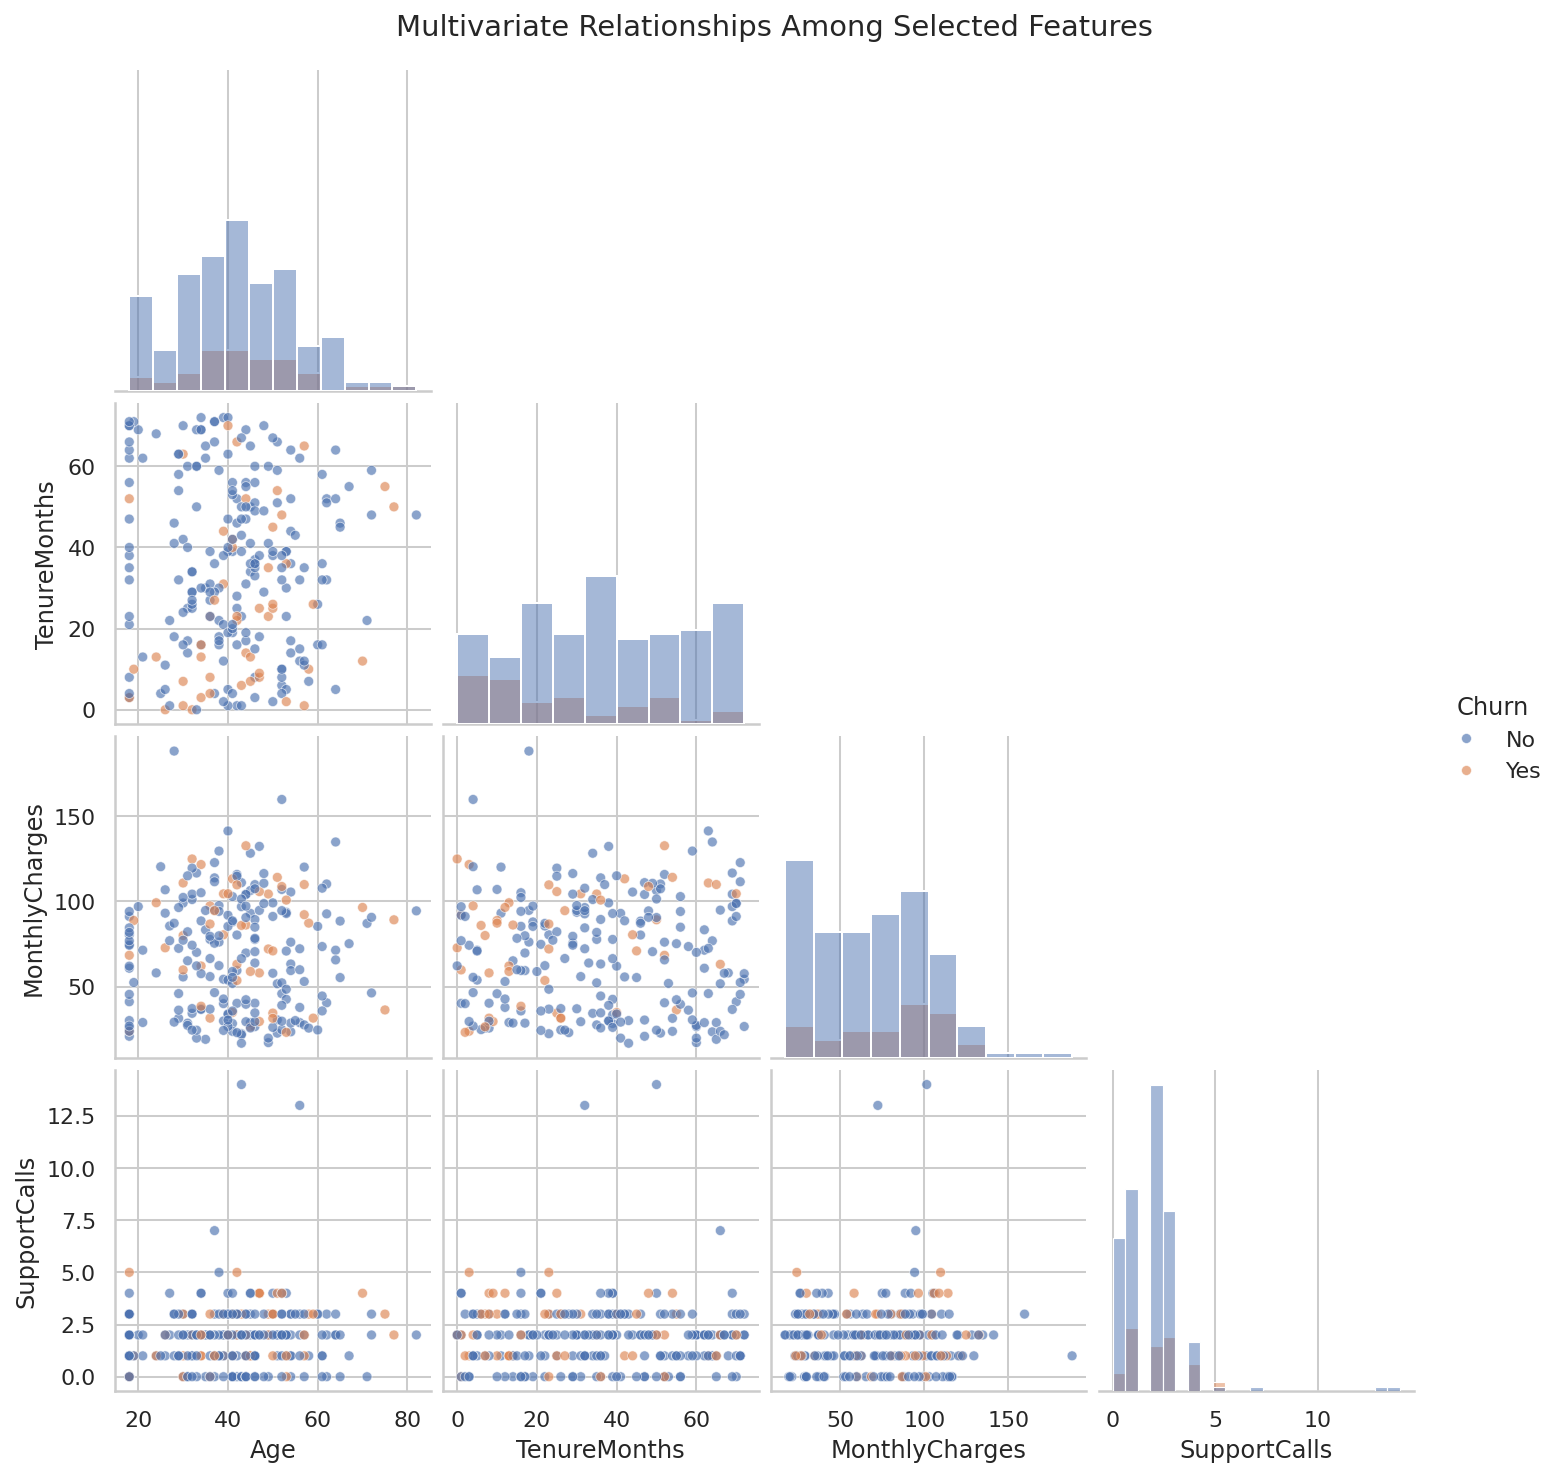

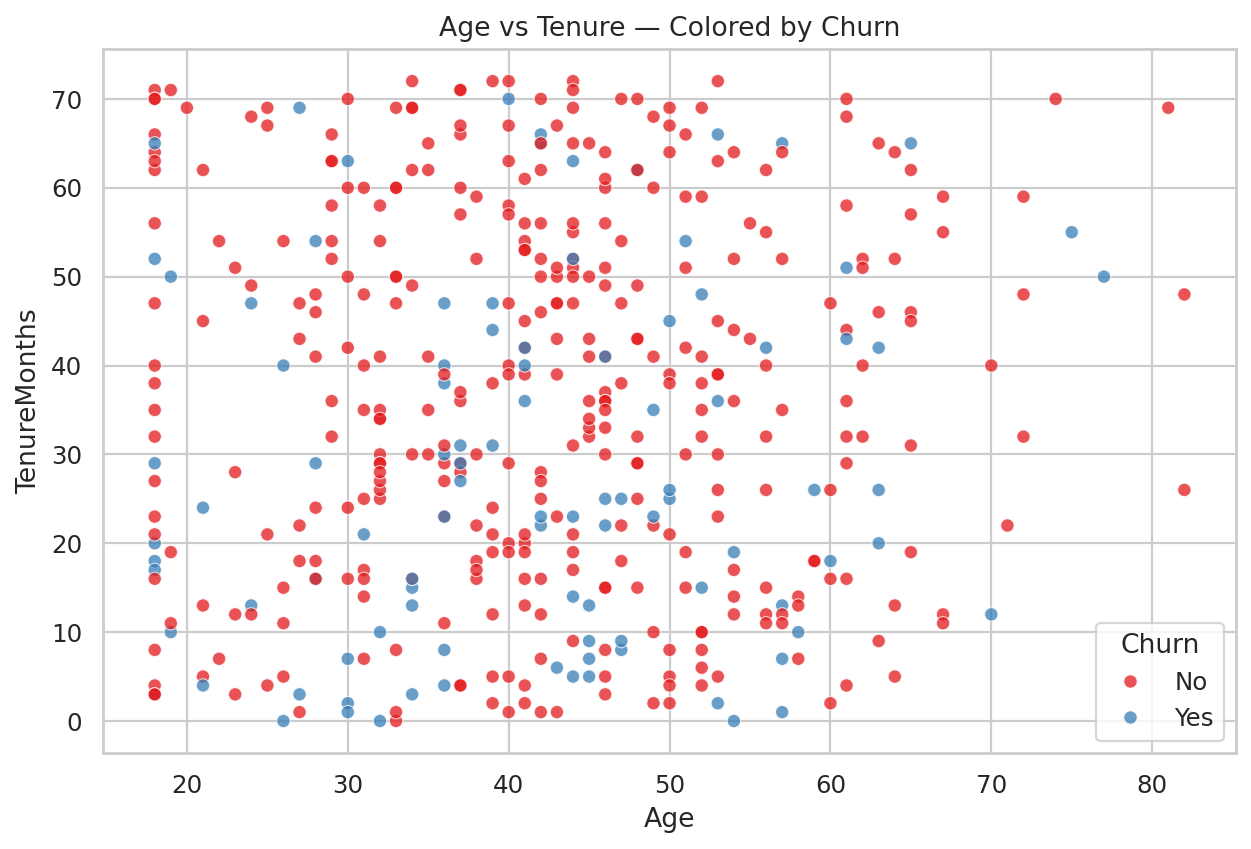

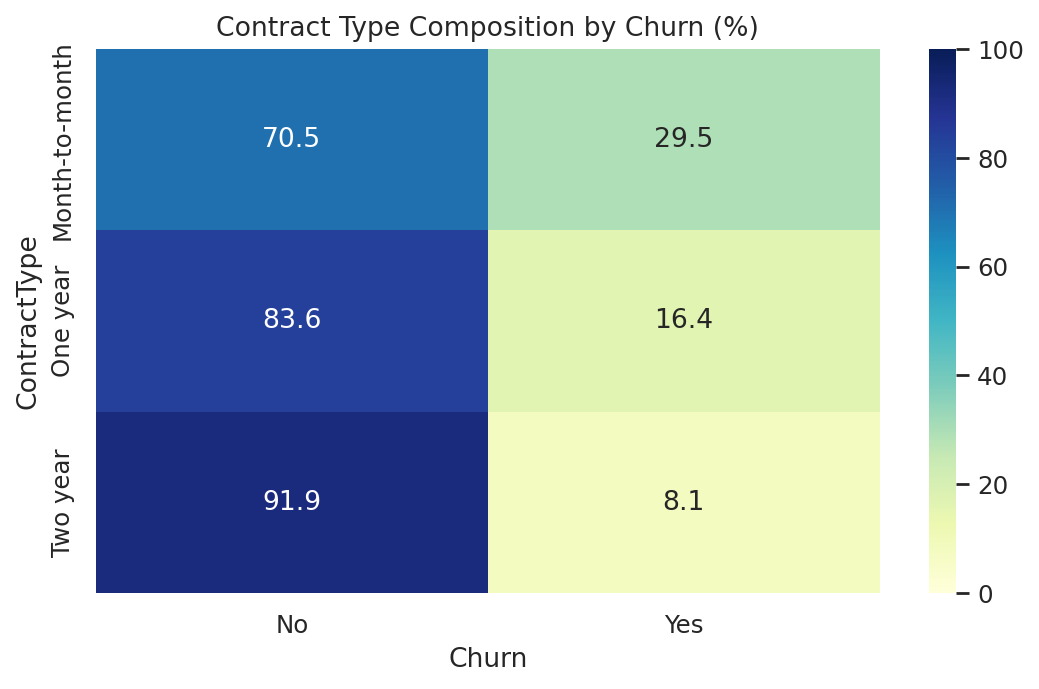

In [14]:
# Display all generated charts inside the notebook output.
for name in run_result["visualizations"]:
    display(Image(filename=str(PROJECT_ROOT / "outputs/figures" / name)))

## 14. Key findings and limitations

Read the generated report at `reports/Week7_EDA_Report.md`. It includes dataset description, methodology, descriptive statistics, categorical frequencies, churn-rate comparisons, correlations, outlier audit, supplementary tests and limitations.

**Interpretation guardrails:**
- The dataset is synthetic and should not support real business claims.
- Churn patterns may reflect the data-generation rule.
- Missing values are not imputed for this descriptive EDA.
- IQR outliers are retained unless investigation establishes that they are invalid.
- Correlation and association tests do not establish causation.

## 15. Export tables and finish

The reusable script writes CSV tables and JSON summaries. Check `outputs/tables/`, `outputs/summary.json`, `outputs/audit_report.json` and the Markdown report.

In [15]:
print("Raw rows:", run_result["raw_rows"])
print("Rows after exact duplicate removal:", run_result["analysis_rows"])
print("Exact duplicates removed:", run_result["duplicate_rows_removed"])
print(f"Churn rate: {run_result['churn_rate_percent']:.2f}%")
print("Visualizations:", run_result["visualization_count"])
print("Report exists:", (PROJECT_ROOT / "reports/Week7_EDA_Report.md").exists())

Raw rows: 508
Rows after exact duplicate removal: 500
Exact duplicates removed: 8
Churn rate: 21.40%
Visualizations: 19
Report exists: True
